# 02 — Extract waveforms

Load the 7 pickup waveforms from every chunk into one array each, shape `(n_shots, 960)`.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))

# PGLA and PKI15A are groups, their trace is in "samples"
WAVEFORMS = {
    "PGIA": "PGIA",
    "PGIP": "PGIP",
    "PGLA": "PGLA/samples",
    "PGRA": "PGRA",
    "PKI15A": "PKI15A/samples",
    "PKI15P": "PKI15P",
    "PKR15A": "PKR15A",
}

In [2]:
waveforms = {name: [] for name in WAVEFORMS}
for path in files:
    with h5py.File(path, "r") as f:
        for name, key in WAVEFORMS.items():
            waveforms[name].append(f[key][:, 0, :])  # (100, 1, 960) -> (100, 960)

waveforms = {name: np.concatenate(arrays) for name, arrays in waveforms.items()}

for name, w in waveforms.items():
    print(f"{name:7s} {w.shape} {w.dtype}")

PGIA    (2100, 960) float64
PGIP    (2100, 960) float64
PGLA    (2100, 960) float64
PGRA    (2100, 960) float64
PKI15A  (2100, 960) float64
PKI15P  (2100, 960) float64
PKR15A  (2100, 960) float64


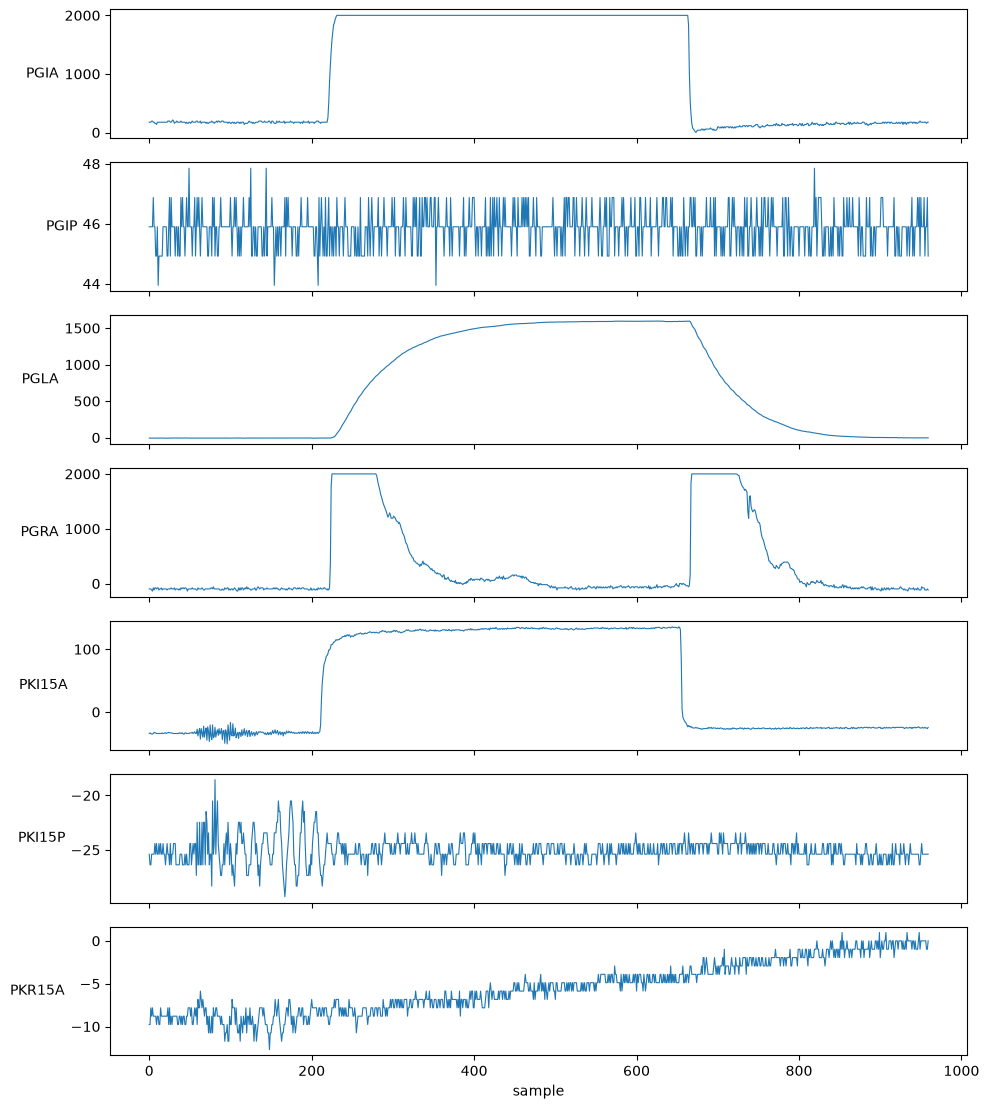

In [3]:
SHOT = 0
fig, axes = plt.subplots(len(waveforms), 1, figsize=(10, 1.6 * len(waveforms)), sharex=True)
for ax, (name, w) in zip(axes, waveforms.items()):
    ax.plot(w[SHOT], lw=0.8)
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
axes[-1].set_xlabel("sample")
fig.tight_layout()

## PGLA: drop on the crest

Just before the falling edge (around sample ~632) the crest drops by ~7 mV and stays low until the waveform falls.

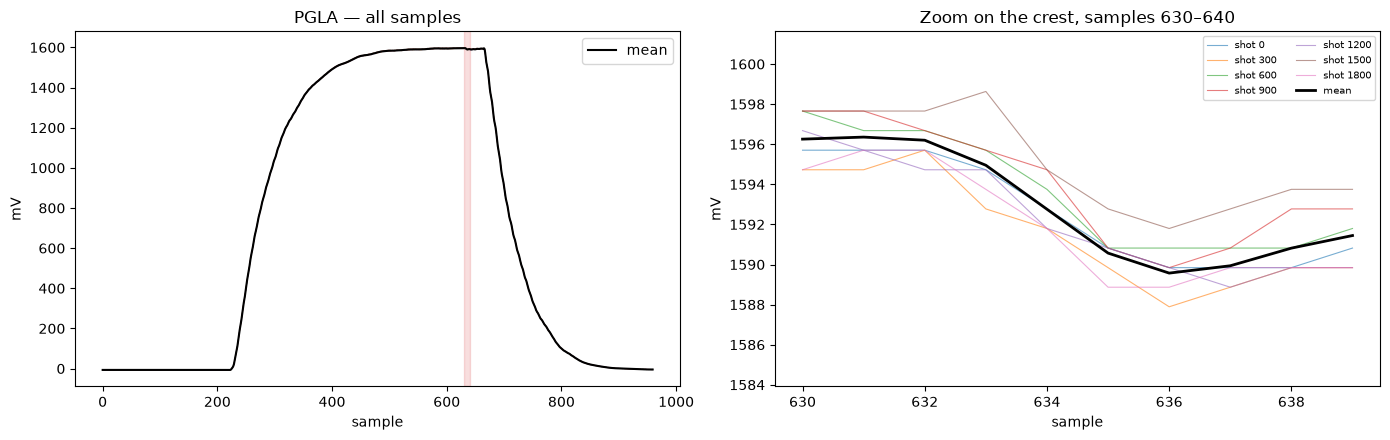

In [4]:
pgla = waveforms["PGLA"]
ZOOM = (630, 640)
SHOTS = range(0, 2100, 300)

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(14, 4.5))

for s in SHOTS:
    ax_full.plot(pgla[s], lw=0.6, alpha=0.6)
    ax_zoom.plot(np.arange(*ZOOM), pgla[s, slice(*ZOOM)], lw=0.8, alpha=0.6, label=f"shot {s}")
ax_full.plot(pgla.mean(axis=0), "k", lw=1.5, label="mean")
ax_zoom.plot(np.arange(*ZOOM), pgla.mean(axis=0)[slice(*ZOOM)], "k", lw=2, label="mean")

ax_full.axvspan(*ZOOM, color="tab:red", alpha=0.15)
ax_full.set(title="PGLA — all samples", xlabel="sample", ylabel="mV")
ax_full.legend()

crest = pgla[list(SHOTS), ZOOM[0]:665]  # stop before the falling edge
ax_zoom.set_ylim(crest.min() - 3, crest.max() + 3)
ax_zoom.set(title=f"Zoom on the crest, samples {ZOOM[0]}–{ZOOM[1]}", xlabel="sample", ylabel="mV")
ax_zoom.legend(fontsize=7, ncol=2)
fig.tight_layout()

## PGLA: size of the drop per shot

Two fixed indices are taken from the **mean waveform**: `I_HIGH` = its max just before the jump (samples 622–632),
`I_LOW` = its min just after it (samples 633–640). For every shot, `drop = pgla[:, I_HIGH] - pgla[:, I_LOW]`.

I_HIGH = 631, I_LOW = 636
drop: median 6.8 mV, 5–95% 4.9–8.8 mV


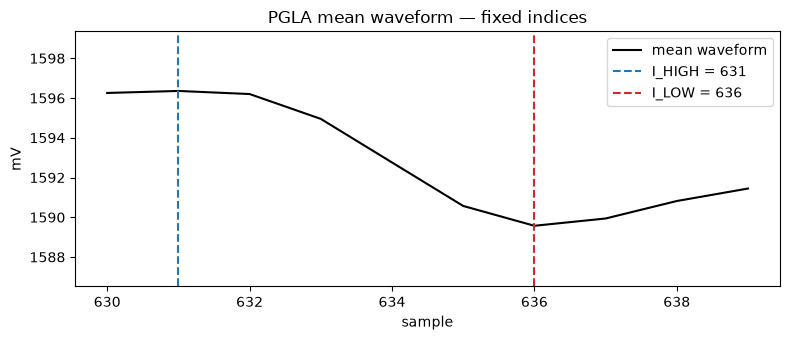

In [5]:
mean_pgla = pgla.mean(axis=0)
I_HIGH = 622 + mean_pgla[622:633].argmax()
I_LOW = 633 + mean_pgla[633:641].argmin()
print(f"I_HIGH = {I_HIGH}, I_LOW = {I_LOW}")

high = pgla[:, I_HIGH]
low = pgla[:, I_LOW]
drop = high - low

print(f"drop: median {np.median(drop):.1f} mV, 5–95% {np.percentile(drop, 5):.1f}–{np.percentile(drop, 95):.1f} mV")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(*ZOOM), mean_pgla[slice(*ZOOM)], "k", lw=1.5, label="mean waveform")
ax.axvline(I_HIGH, color="tab:blue", ls="--", label=f"I_HIGH = {I_HIGH}")
ax.axvline(I_LOW, color="tab:red", ls="--", label=f"I_LOW = {I_LOW}")
ax.set_ylim(mean_pgla[ZOOM[0]:665].min() - 3, mean_pgla[ZOOM[0]:665].max() + 3)
ax.set(xlabel="sample", ylabel="mV", title="PGLA mean waveform — fixed indices")
ax.legend()
fig.tight_layout()

## Drop vs BCM_GUN

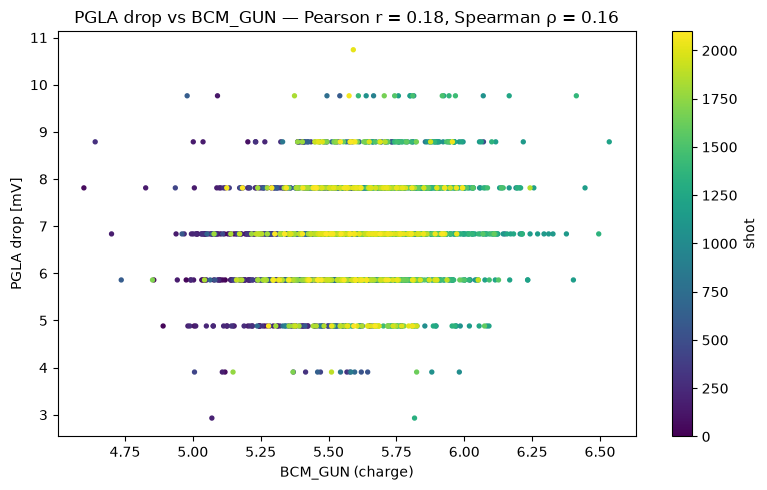

In [6]:
bcm_gun = np.concatenate([h5py.File(path, "r")["BCM_GUN"][:] for path in files])


def spearman(x, y):
    return np.corrcoef(x.argsort().argsort(), y.argsort().argsort())[0, 1]


pearson = np.corrcoef(bcm_gun, drop)[0, 1]
rho = spearman(bcm_gun, drop)

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(bcm_gun, drop, c=np.arange(len(drop)), s=8, cmap="viridis")
fig.colorbar(sc, ax=ax, label="shot")
ax.set(xlabel="BCM_GUN (charge)", ylabel="PGLA drop [mV]",
       title=f"PGLA drop vs BCM_GUN — Pearson r = {pearson:.2f}, Spearman ρ = {rho:.2f}")
fig.tight_layout()

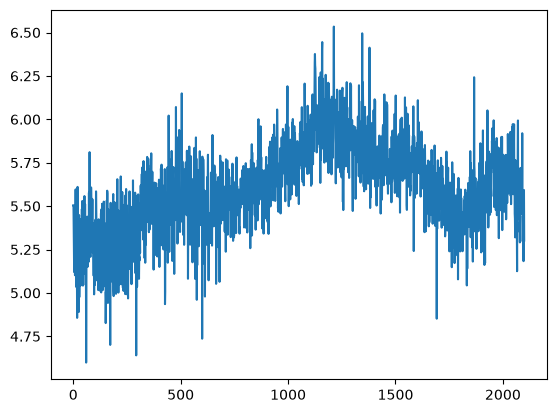

In [7]:
plt.plot(bcm_gun)
plt.show()

## PGIA, PGIP, PGRA: same zoom region as the PGLA crest

Note: PGIA is saturated at ~2000 mV over the whole crest, PGIP is flat noise, and PGRA is still on its baseline
in this region (its pulse starts at ~668).

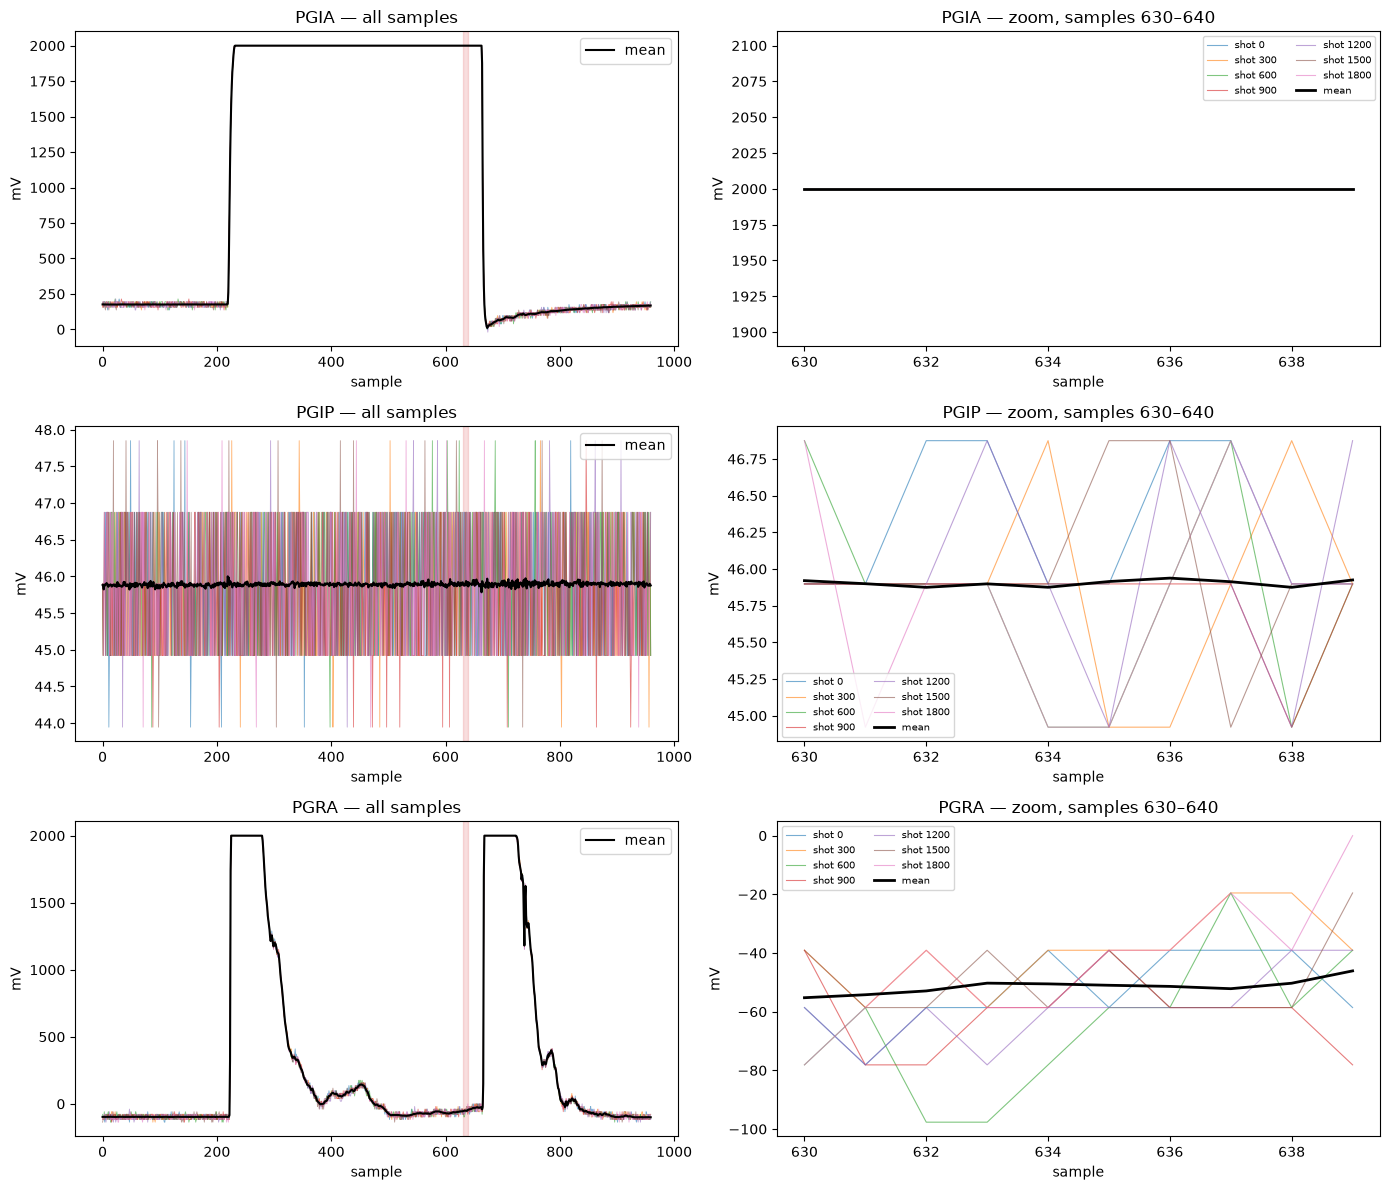

In [8]:
CREST = (630, 640)
names = ["PGIA", "PGIP", "PGRA"]

fig, axes = plt.subplots(len(names), 2, figsize=(14, 4 * len(names)))
for (ax_full, ax_zoom), name in zip(axes, names):
    w = waveforms[name]
    mean_w = w.mean(axis=0)
    x = np.arange(*CREST)
    for s in SHOTS:
        ax_full.plot(w[s], lw=0.6, alpha=0.6)
        ax_zoom.plot(x, w[s, slice(*CREST)], lw=0.8, alpha=0.6, label=f"shot {s}")
    ax_full.plot(mean_w, "k", lw=1.5, label="mean")
    ax_zoom.plot(x, mean_w[slice(*CREST)], "k", lw=2, label="mean")

    ax_full.axvspan(*CREST, color="tab:red", alpha=0.15)
    ax_full.set(title=f"{name} — all samples", xlabel="sample", ylabel="mV")
    ax_full.legend()
    ax_zoom.set(title=f"{name} — zoom, samples {CREST[0]}–{CREST[1]}", xlabel="sample", ylabel="mV")
    ax_zoom.legend(fontsize=7, ncol=2)
fig.tight_layout()

## Klystron traces: PKI15A, PKI15P, PKR15A

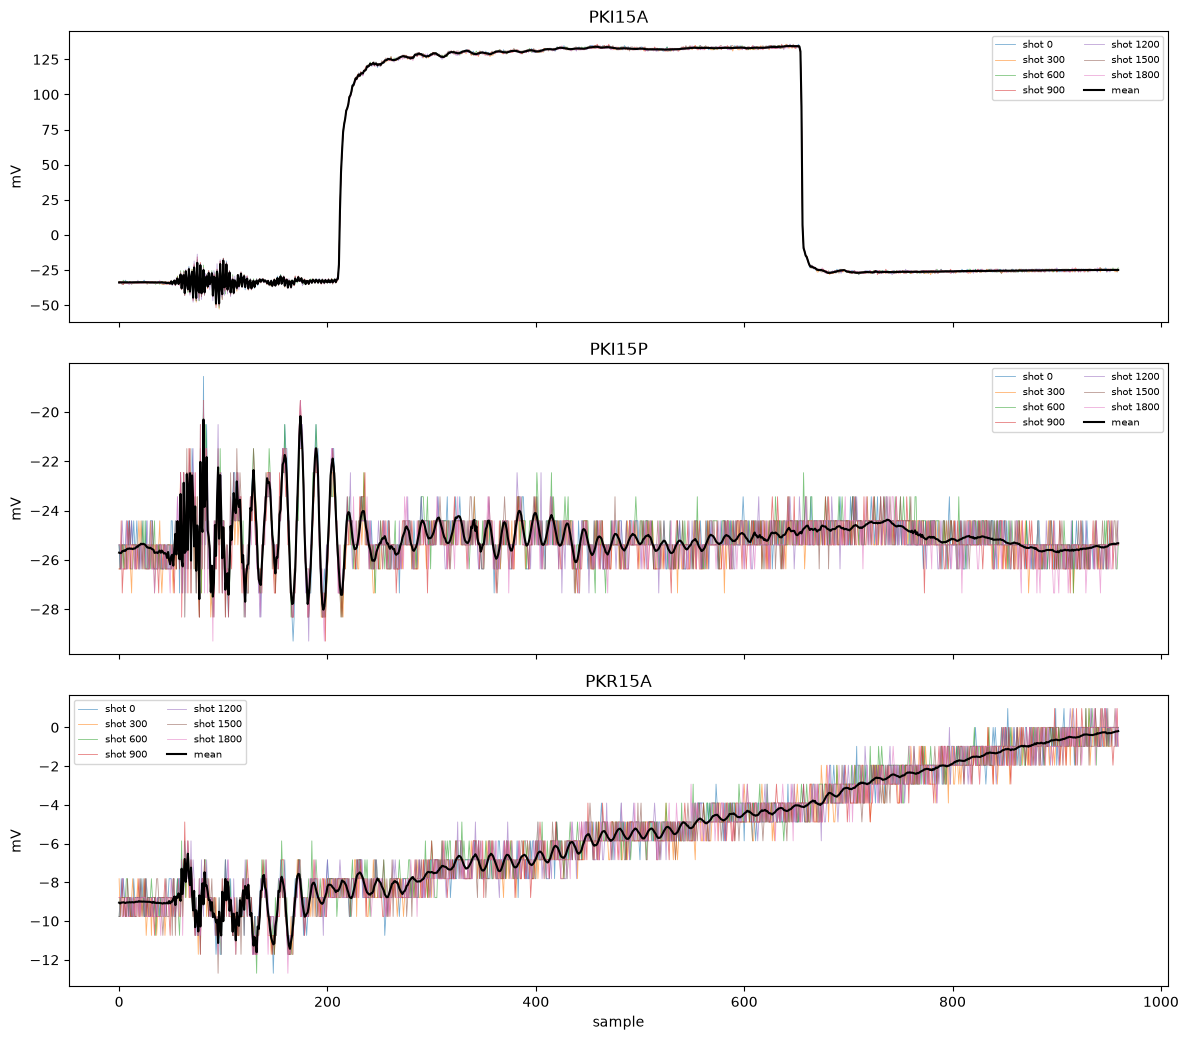

In [9]:
names = ["PKI15A", "PKI15P", "PKR15A"]

fig, axes = plt.subplots(len(names), 1, figsize=(12, 3.5 * len(names)), sharex=True)
for ax, name in zip(axes, names):
    w = waveforms[name]
    for s in SHOTS:
        ax.plot(w[s], lw=0.6, alpha=0.6, label=f"shot {s}")
    ax.plot(w.mean(axis=0), "k", lw=1.5, label="mean")
    ax.set(title=name, ylabel="mV")
    ax.legend(fontsize=7, ncol=2)
axes[-1].set_xlabel("sample")
fig.tight_layout()